# ДЗ. Морфологические операции и анализ объектов

Старинская Светлана, 3ФИИТ

## Задание

Сравнить формы и размеры ядер, обработать реальное изображение, исследовать min_area, периметры, контуры и связные компоненты.

## 1. Импорт библиотек и тестовое изображение

Используем binary_demo из практики: прямоугольник, круг, символ, шум и разрывы.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
SEED=42
np.random.seed(SEED)
OUT=Path('results_07');OUT.mkdir(exist_ok=True)

In [2]:
def create_morphology_demo_image():
    """
    Создает синтетическое бинарное изображение
    с объектами, шумом и разрывами.
    """
    img = np.zeros((220, 320), dtype=np.uint8)

    # Основные объекты
    cv2.rectangle(img, (30, 40), (120, 170), 255, -1)
    cv2.circle(img, (220, 90), 40, 255, -1)
    cv2.putText(img, "A", (180, 190),
                cv2.FONT_HERSHEY_SIMPLEX, 2, 255, 5)

    # Искусственные "дыры" в объектах
    cv2.circle(img, (70, 100), 10, 0, -1)
    cv2.rectangle(img, (210, 80), (225, 95), 0, -1)

    # Разрывы
    cv2.line(img, (30, 100), (120, 100), 0, 3)

    # Белый шум
    np.random.seed(42)
    for _ in range(120):
        x = np.random.randint(0, img.shape[1])
        y = np.random.randint(0, img.shape[0])
        img[y, x] = 255

    return img
binary_demo = create_morphology_demo_image()


## 2. Форма и размер ядра

Для каждой формы исследуем размеры 3×3, 5×5 и 9×9. Отдельно показываем opening и closing.

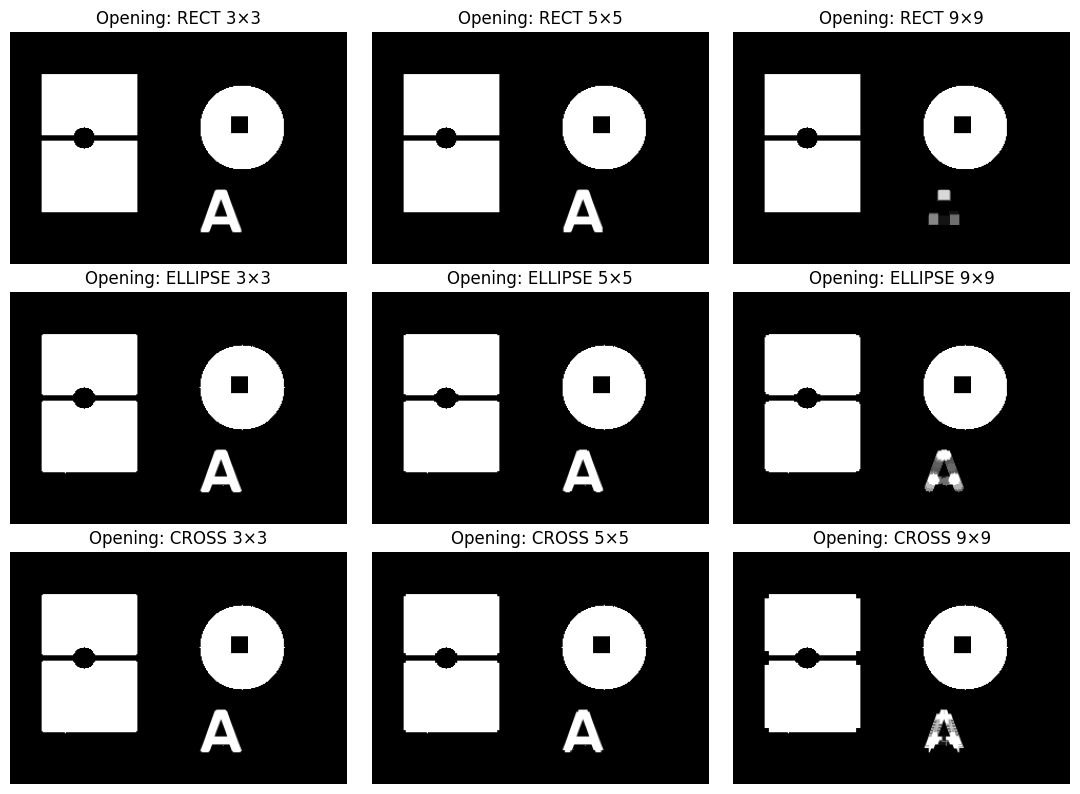

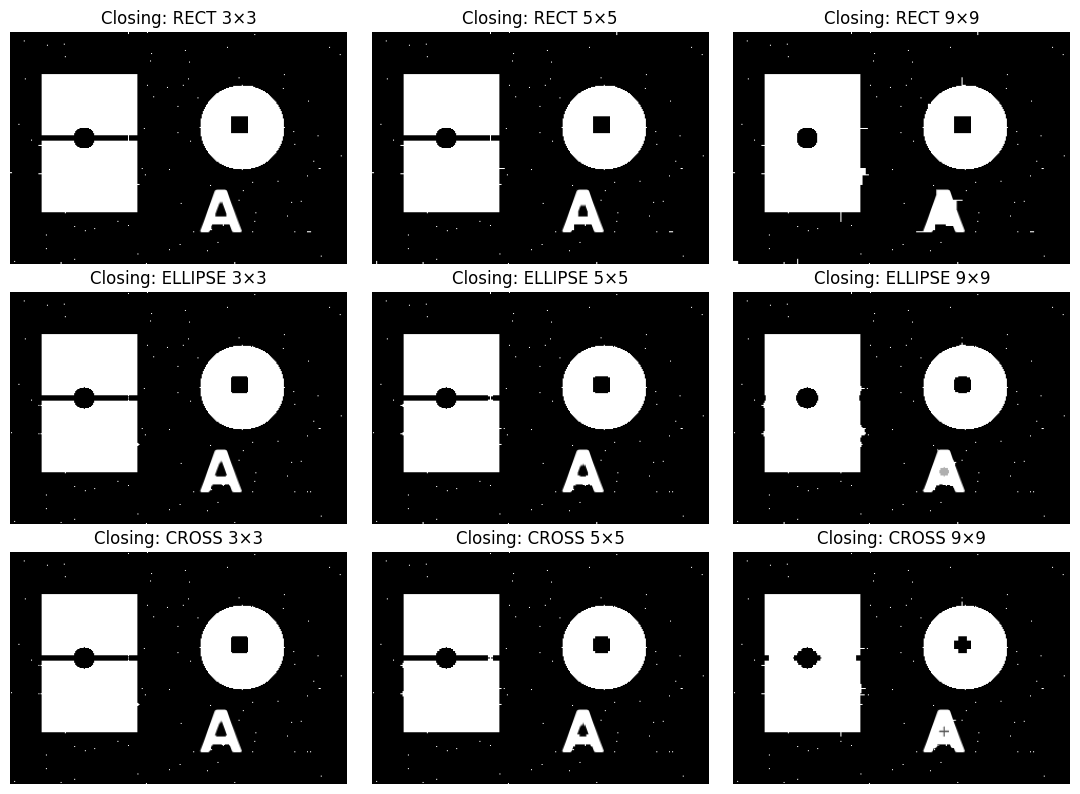

In [3]:
shapes={'RECT':cv2.MORPH_RECT,'ELLIPSE':cv2.MORPH_ELLIPSE,'CROSS':cv2.MORPH_CROSS}
for op_name,op in [('Opening',cv2.MORPH_OPEN),('Closing',cv2.MORPH_CLOSE)]:
    fig,axes=plt.subplots(3,3,figsize=(11,8))
    for i,(name,shape) in enumerate(shapes.items()):
        for j,size in enumerate([3,5,9]):
            result=cv2.morphologyEx(binary_demo,op,cv2.getStructuringElement(shape,(size,size)))
            axes[i,j].imshow(result,cmap='gray');axes[i,j].set_title(f'{op_name}: {name} {size}×{size}');axes[i,j].axis('off')
    plt.tight_layout();plt.show()

Одиночные белые точки удаляются opening со всеми тремя ядрами при размере 3×3 и больше. ELLIPSE лучше соответствует круглым объектам. RECT закрывает разрывы сразу по нескольким направлениям; CROSS удобен для горизонтальных и вертикальных линий. Большое ядро сильнее меняет форму и может удалить тонкие части символа.

## 3. Реальное изображение

Берём фотографию муравья из предыдущей работы. Для воспроизводимости копия ant.jpg находится рядом с ноутбуком. Сохраняем каждый этап.

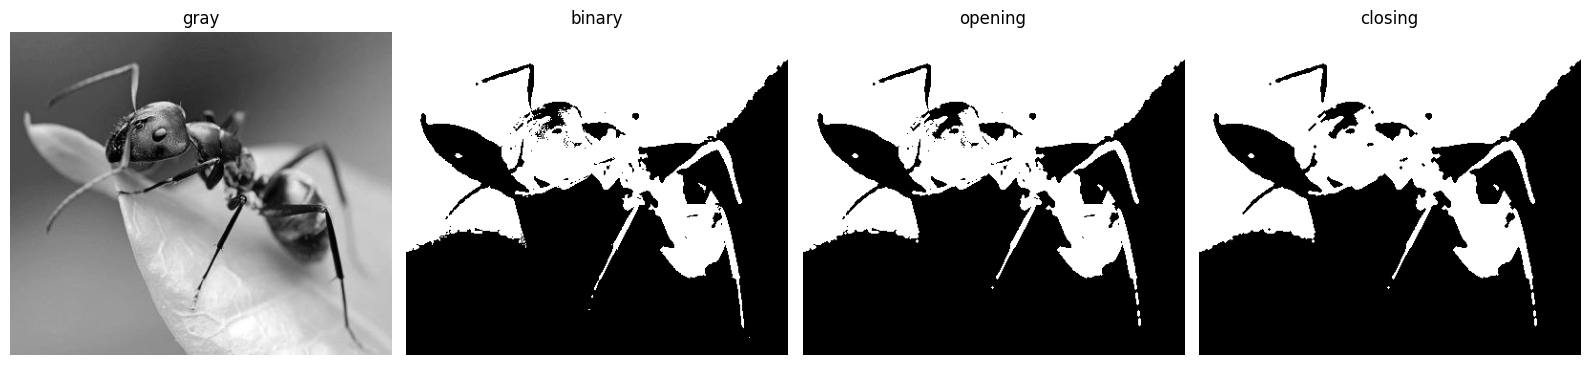

In [4]:
image=cv2.imread('ant.jpg')
if image is None:raise FileNotFoundError('Нужна фотография ant.jpg рядом с ноутбуком')
gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
_,binary=cv2.threshold(gray,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3))
opened=cv2.morphologyEx(binary,cv2.MORPH_OPEN,kernel)
closed=cv2.morphologyEx(opened,cv2.MORPH_CLOSE,kernel)
fig,axes=plt.subplots(1,4,figsize=(16,4))
for ax,(name,a) in zip(axes,{'gray':gray,'binary':binary,'opening':opened,'closing':closed}.items()):
    cv2.imwrite(str(OUT/f'{name}.png'),a)
    ax.imshow(a,cmap='gray');ax.set_title(name);ax.axis('off')
plt.tight_layout();plt.show()

## 4. Площадь, периметр и порог фильтрации

Компактность оцениваем как 4πS/P². Площадь контура геометрическая, площадь компоненты — число пикселей, поэтому они могут различаться.

min_area = 1 | найдено: 7
min_area = 20 | найдено: 2
min_area = 100 | найдено: 1
min_area = 500 | найдено: 1
min_area = 2000 | найдено: 1
Объект 1: площадь=62857.0, периметр=2804.5, компактность=0.100
Компонента: 1 bbox/площадь: [0, 0, 400, 271, 62043] центр: [182.3768193  95.0641007]


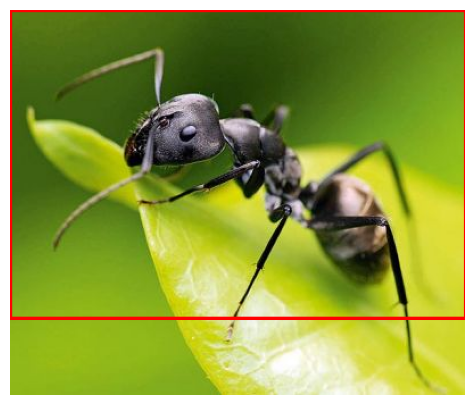

In [5]:
def analyze_objects(mask,min_area):
    contours,_=cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    result=[]
    for contour in contours:
        area=cv2.contourArea(contour);perimeter=cv2.arcLength(contour,True)
        if area>=min_area and perimeter>0:
            result.append((contour,area,perimeter,4*np.pi*area/perimeter**2))
    return result
for threshold in [1,20,100,500,2000]:
    print('min_area =',threshold,'| найдено:',len(analyze_objects(closed,threshold)))
objects=analyze_objects(closed,100)
boxed=image.copy()
for i,(contour,area,perimeter,compact) in enumerate(objects,1):
    x,y,w,h=cv2.boundingRect(contour)
    cv2.rectangle(boxed,(x,y),(x+w,y+h),(0,0,255),2)
    print(f'Объект {i}: площадь={area:.1f}, периметр={perimeter:.1f}, компактность={compact:.3f}')
cv2.imwrite(str(OUT/'objects.png'),boxed)
plt.figure(figsize=(9,5));plt.imshow(cv2.cvtColor(boxed,cv2.COLOR_BGR2RGB));plt.axis('off');plt.show()
count,labels,stats,centers=cv2.connectedComponentsWithStats(closed,connectivity=8)
for index in range(1,count):
    if stats[index,cv2.CC_STAT_AREA]>=100:print('Компонента:',index,'bbox/площадь:',stats[index].tolist(),'центр:',centers[index])

## 5. Компактность объектов

Сравним площади, периметры и компактность нескольких объектов демонстрационного изображения.

In [6]:
for i, (_, area, perimeter, compact) in enumerate(analyze_objects(binary_demo, 100), 1):
    print(f"Объект {i}: S={area:.1f}, P={perimeter:.1f}, компактность={compact:.3f}")


Объект 1: S=889.5, P=153.2, компактность=0.477
Объект 2: S=5919.0, P=323.8, компактность=0.709
Объект 3: S=4913.0, P=264.6, компактность=0.882
Объект 4: S=5018.0, P=303.0, компактность=0.687


## Вывод

Opening удаляет одиночный шум при всех трёх формах ядра. ELLIPSE лучше соответствует круглым границам; RECT соединяет разрывы по нескольким направлениям. При увеличении ядра до 9×9 сильнее искажаются тонкие части символа. Малый min_area оставляет шум, большой удаляет детали.

Контуры удобны для площади, периметра и компактности; связные компоненты дают площадь в пикселях, центр и рамку. Круг имеет более высокую компактность, чем вытянутые и разветвлённые объекты.

На реальной фотографии качество сегментации низкое: тёмный фон сливается с муравьём. При min_area=100 остаётся одна крупная область с компактностью 0,100, рамка охватывает почти всю ширину снимка. Морфология очищает маску, но не исправляет ошибку глобальной бинаризации Оцу. Для этой фотографии нужен контролируемый фон или более сложная сегментация. Все промежуточные изображения и итоговая рамка сохранены в results_07.